In [ ]:
# !pip install optuna -q

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

from statsmodels.graphics.mosaicplot import mosaic

# import optuna

In [ ]:
data = pd.read_csv('https://github.com/evanhfw/project-pdm/raw/refs/heads/main/heart.csv')

HTTPError: HTTP Error 404: Not Found

In [ ]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [ ]:
# get the number of missing data points per column
missing_values_count = data.isnull().sum()
missing_values_count

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


# EDA

In [ ]:
data = pd.read_csv('https://github.com/evanhfw/project-pdm/raw/refs/heads/main/heart.csv')
data['sex'] = data['sex'].astype('category')
data['cp'] = data['cp'].astype('category')
data['fbs'] = data['fbs'].astype('category')
data['restecg'] = data['restecg'].astype('category')
data['exang'] = data['exang'].astype('category')
data['slope'] = data['slope'].astype('category')
data['ca'] = data['ca'].astype('category')
data['ca'] = data['ca'].astype('category')
data['thal'] = data['thal'].astype('category')
data['target'] = data['target'].astype('category')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       303 non-null    int64   
 1   sex       303 non-null    category
 2   cp        303 non-null    category
 3   trestbps  303 non-null    int64   
 4   chol      303 non-null    int64   
 5   fbs       303 non-null    category
 6   restecg   303 non-null    category
 7   thalach   303 non-null    int64   
 8   exang     303 non-null    category
 9   oldpeak   303 non-null    float64 
 10  slope     303 non-null    category
 11  ca        303 non-null    category
 12  thal      303 non-null    category
 13  target    303 non-null    category
dtypes: category(9), float64(1), int64(4)
memory usage: 16.0 KB


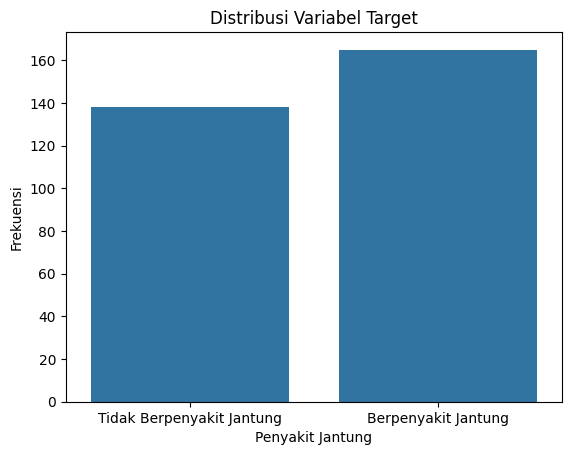

In [ ]:
sns.countplot(x='target', data=data)
plt.title('Distribusi Variabel Target')
plt.xlabel('Penyakit Jantung')
plt.ylabel('Frekuensi')
plt.xticks([0, 1], ['Tidak Berpenyakit Jantung', 'Berpenyakit Jantung'])
plt.show()

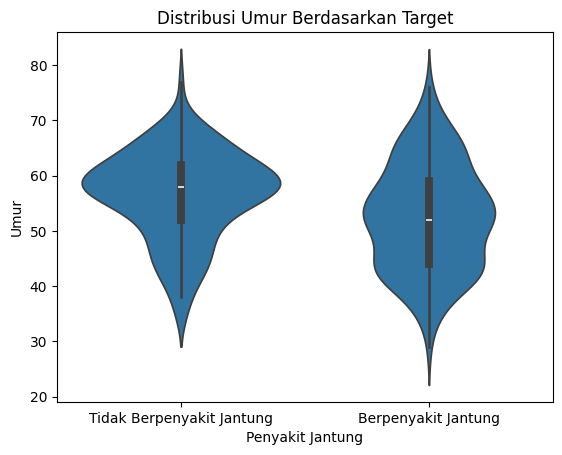

In [ ]:
sns.violinplot(data, x='target', y='age')
plt.title(f'Distribusi Umur Berdasarkan Target')
plt.ylabel('Umur')
plt.xlabel('Penyakit Jantung')
plt.xticks([0, 1], ['Tidak Berpenyakit Jantung', 'Berpenyakit Jantung'])
plt.show()

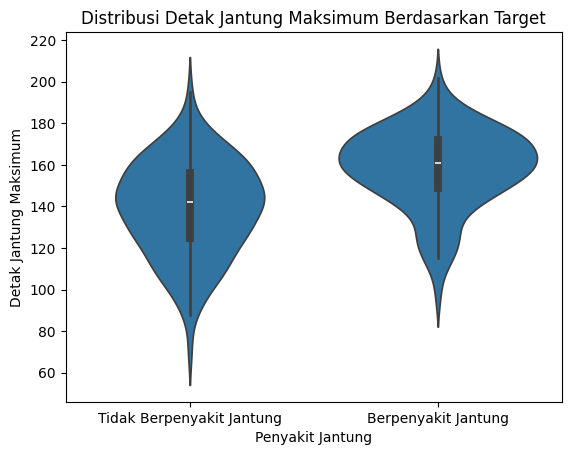

In [ ]:
sns.violinplot(x='target', y='thalach', data=data)
plt.title('Distribusi Detak Jantung Maksimum Berdasarkan Target')
plt.xlabel('Penyakit Jantung')
plt.ylabel('Detak Jantung Maksimum')
plt.xticks([0, 1], ['Tidak Berpenyakit Jantung', 'Berpenyakit Jantung'])
plt.show()

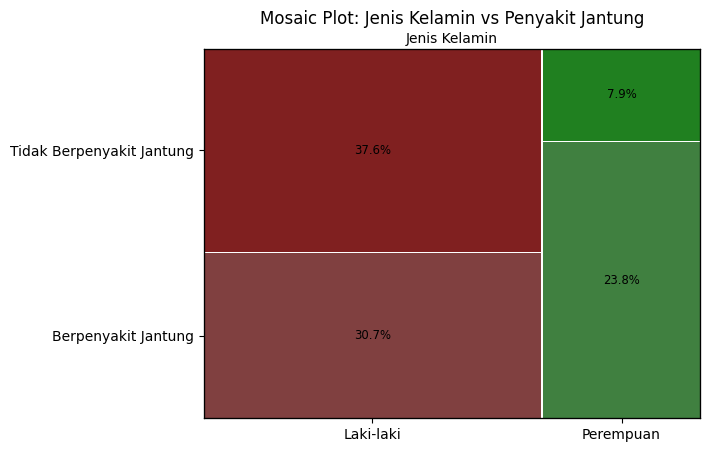

In [ ]:
# Buat tabel kontingensi dengan memastikan tipe data adalah string untuk `sex` dan `target`
data['sex'] = data['sex'].astype(str)       # Pastikan tipe data 'sex' adalah string
data['target'] = data['target'].astype(str) # Pastikan tipe data 'target' adalah string

# Buat tabel kontingensi
cross_tab = pd.crosstab(data['sex'].replace({'0': 'Perempuan', '1': 'Laki-laki'}), data['target'].replace({'0': 'Tidak Berpenyakit Jantung', '1': 'Berpenyakit Jantung'}))

# Hitung proporsi dari setiap sel
total = cross_tab.sum().sum()  # Total keseluruhan data
proporsi_data = cross_tab / total  # Menghitung proporsi setiap sel
mosaic_data = proporsi_data.stack().to_dict()  # Konversi ke dictionary

# Fungsi untuk menampilkan persentase pada plot mosaic
def labelizer(key):
    value = mosaic_data[key]
    return f'{value*100:.1f}%'  # Format label dalam persen

# Plot mosaic dengan label persentase
mosaic(mosaic_data, title='Mosaic Plot: Jenis Kelamin vs Penyakit Jantung', labelizer=labelizer)
plt.xlabel('Jenis Kelamin')
plt.ylabel('Proporsi')
plt.show()

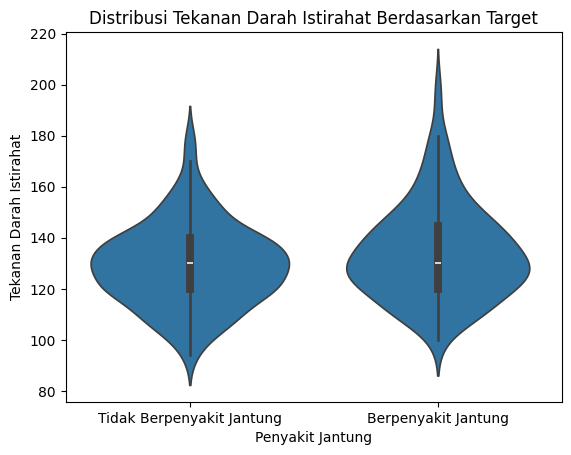

In [ ]:
sns.violinplot(data, x='target', y='trestbps')
plt.title(f'Distribusi Tekanan Darah Istirahat Berdasarkan Target')
plt.ylabel('Tekanan Darah Istirahat')
plt.xlabel('Penyakit Jantung')
plt.xticks([0, 1], ['Tidak Berpenyakit Jantung', 'Berpenyakit Jantung'])
plt.show()

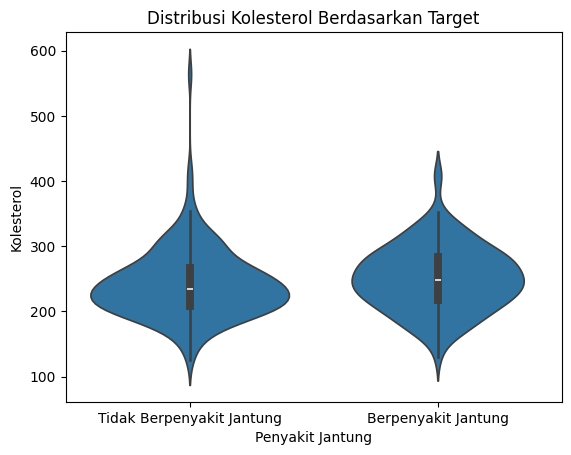

In [ ]:
sns.violinplot(data, x='target', y='chol')
plt.title(f'Distribusi Kolesterol Berdasarkan Target')
plt.ylabel('Kolesterol')
plt.xlabel('Penyakit Jantung')
plt.xticks([0, 1], ['Tidak Berpenyakit Jantung', 'Berpenyakit Jantung'])
plt.show()

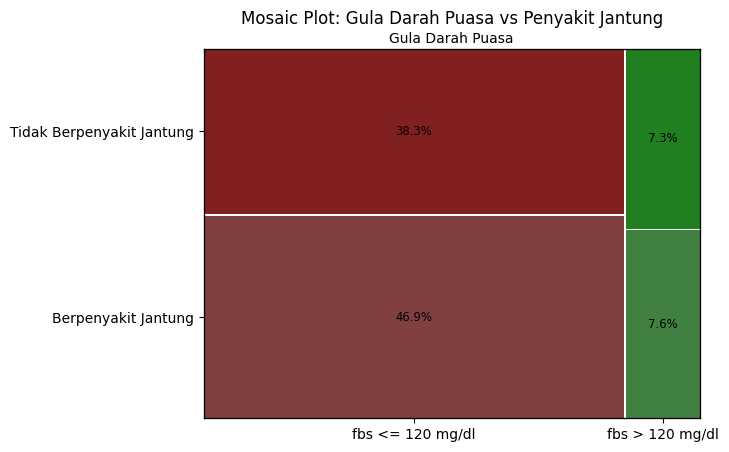

In [ ]:
# Buat tabel kontingensi dengan memastikan tipe data adalah string untuk `sex` dan `target`
data['fbs'] = data['fbs'].astype(str)       # Pastikan tipe data 'sex' adalah string
data['target'] = data['target'].astype(str) # Pastikan tipe data 'target' adalah string

# Buat tabel kontingensi
cross_tab = pd.crosstab(data['fbs'].replace({'0': 'fbs <= 120 mg/dl', '1': 'fbs > 120 mg/dl'}), data['target'].replace({'0': 'Tidak Berpenyakit Jantung', '1': 'Berpenyakit Jantung'}))

# Hitung proporsi dari setiap sel
total = cross_tab.sum().sum()  # Total keseluruhan data
proporsi_data = cross_tab / total  # Menghitung proporsi setiap sel
mosaic_data = proporsi_data.stack().to_dict()  # Konversi ke dictionary

# Fungsi untuk menampilkan persentase pada plot mosaic
def labelizer(key):
    value = mosaic_data[key]
    return f'{value*100:.1f}%'  # Format label dalam persen

# Plot mosaic dengan label persentase
mosaic(mosaic_data, title='Mosaic Plot: Gula Darah Puasa vs Penyakit Jantung', labelizer=labelizer)
plt.xlabel('Gula Darah Puasa')
plt.ylabel('Proporsi')
plt.show()

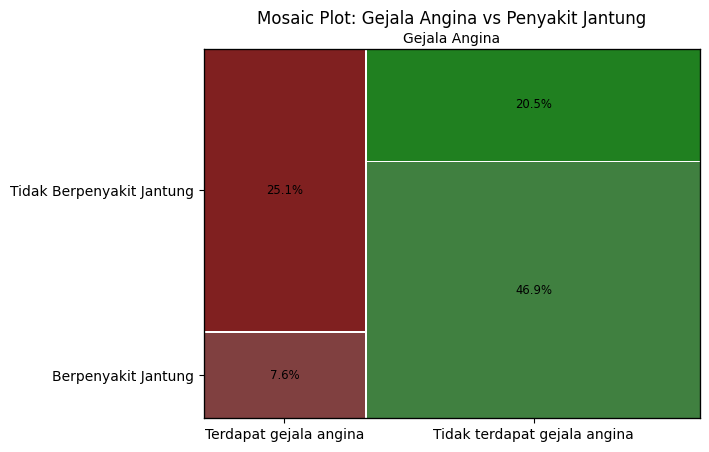

In [ ]:
# Buat tabel kontingensi dengan memastikan tipe data adalah string untuk `sex` dan `target`
data['exang'] = data['exang'].astype(str)       # Pastikan tipe data 'sex' adalah string
data['target'] = data['target'].astype(str) # Pastikan tipe data 'target' adalah string

# Buat tabel kontingensi
cross_tab = pd.crosstab(data['exang'].replace({'0': 'Tidak terdapat gejala angina', '1': 'Terdapat gejala angina'}), data['target'].replace({'0': 'Tidak Berpenyakit Jantung', '1': 'Berpenyakit Jantung'}))

# Hitung proporsi dari setiap sel
total = cross_tab.sum().sum()  # Total keseluruhan data
proporsi_data = cross_tab / total  # Menghitung proporsi setiap sel
mosaic_data = proporsi_data.stack().to_dict()  # Konversi ke dictionary

# Fungsi untuk menampilkan persentase pada plot mosaic
def labelizer(key):
    value = mosaic_data[key]
    return f'{value*100:.1f}%'  # Format label dalam persen

# Plot mosaic dengan label persentase
mosaic(mosaic_data, title='Mosaic Plot: Gejala Angina vs Penyakit Jantung', labelizer=labelizer)
plt.xlabel('Gejala Angina')
plt.ylabel('Proporsi')
plt.show()

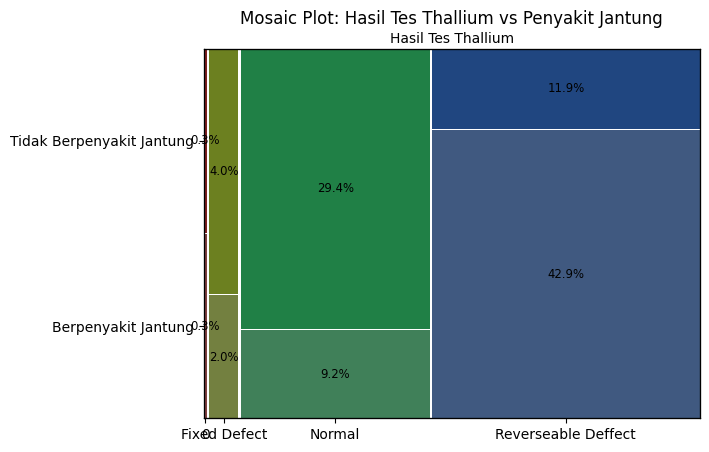

In [ ]:
# Buat tabel kontingensi dengan memastikan tipe data adalah string untuk `sex` dan `target`
data['thal'] = data['thal'].astype(str)       # Pastikan tipe data 'sex' adalah string
data['target'] = data['target'].astype(str) # Pastikan tipe data 'target' adalah string

# Buat tabel kontingensi
cross_tab = pd.crosstab(data['thal'].replace({'1': 'Fixed Defect', '2': 'Reverseable Deffect', '3': 'Normal'}), data['target'].replace({'0': 'Tidak Berpenyakit Jantung', '1': 'Berpenyakit Jantung'}))

# Hitung proporsi dari setiap sel
total = cross_tab.sum().sum()  # Total keseluruhan data
proporsi_data = cross_tab / total  # Menghitung proporsi setiap sel
mosaic_data = proporsi_data.stack().to_dict()  # Konversi ke dictionary

# Fungsi untuk menampilkan persentase pada plot mosaic
def labelizer(key):
    value = mosaic_data[key]
    return f'{value*100:.1f}%'  # Format label dalam persen

# Plot mosaic dengan label persentase
mosaic(mosaic_data, title='Mosaic Plot: Hasil Tes Thallium vs Penyakit Jantung', labelizer=labelizer)
plt.xlabel('Hasil Tes Thallium')
plt.ylabel('Proporsi')
plt.show()

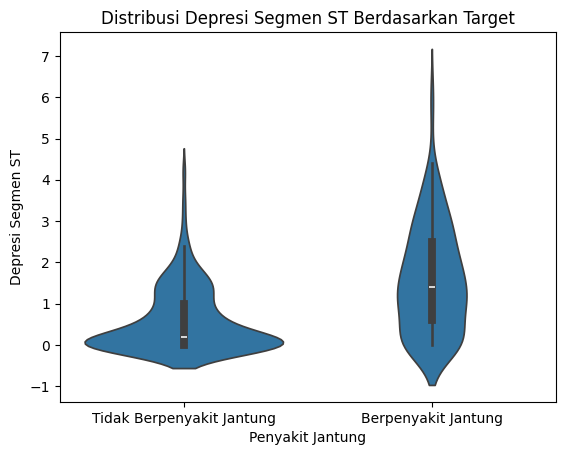

In [ ]:
sns.violinplot(data, x='target', y='oldpeak')
plt.title(f'Distribusi Depresi Segmen ST Berdasarkan Target')
plt.ylabel('Depresi Segmen ST')
plt.xlabel('Penyakit Jantung')
plt.xticks([0, 1], ['Tidak Berpenyakit Jantung', 'Berpenyakit Jantung'])
plt.show()

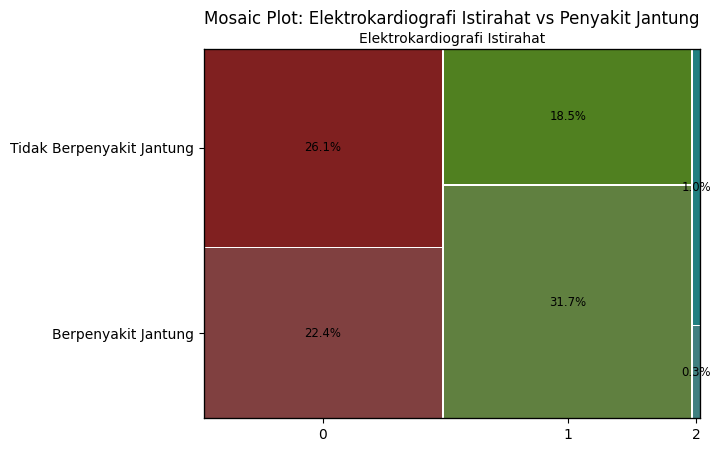

In [ ]:
# Buat tabel kontingensi dengan memastikan tipe data adalah string untuk `sex` dan `target`
data['restecg'] = data['restecg'].astype(str)       # Pastikan tipe data 'sex' adalah string
data['target'] = data['target'].astype(str) # Pastikan tipe data 'target' adalah string

# Buat tabel kontingensi
cross_tab = pd.crosstab(data['restecg'], data['target'].replace({'0': 'Tidak Berpenyakit Jantung', '1': 'Berpenyakit Jantung'}))

# Hitung proporsi dari setiap sel
total = cross_tab.sum().sum()  # Total keseluruhan data
proporsi_data = cross_tab / total  # Menghitung proporsi setiap sel
mosaic_data = proporsi_data.stack().to_dict()  # Konversi ke dictionary

# Fungsi untuk menampilkan persentase pada plot mosaic
def labelizer(key):
    value = mosaic_data[key]
    return f'{value*100:.1f}%'  # Format label dalam persen

# Plot mosaic dengan label persentase
mosaic(mosaic_data, title='Mosaic Plot: Elektrokardiografi Istirahat vs Penyakit Jantung', labelizer=labelizer)
plt.xlabel('Elektrokardiografi Istirahat')
plt.ylabel('Proporsi')
plt.show()

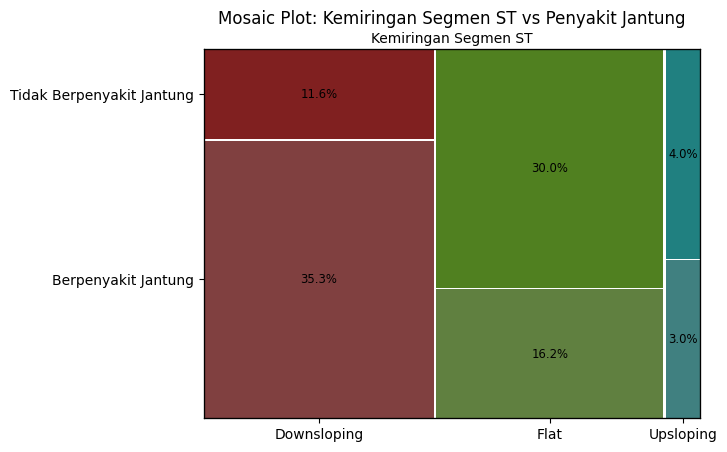

In [ ]:
# Buat tabel kontingensi dengan memastikan tipe data adalah string untuk `sex` dan `target`
data['slope'] = data['slope'].astype(str)       # Pastikan tipe data 'sex' adalah string
data['target'] = data['target'].astype(str) # Pastikan tipe data 'target' adalah string

# Buat tabel kontingensi
cross_tab = pd.crosstab(data['slope'].replace({'0': 'Upsloping', '1': 'Flat', '2': 'Downsloping'}), data['target'].replace({'0': 'Tidak Berpenyakit Jantung', '1': 'Berpenyakit Jantung'}))

# Hitung proporsi dari setiap sel
total = cross_tab.sum().sum()  # Total keseluruhan data
proporsi_data = cross_tab / total  # Menghitung proporsi setiap sel
mosaic_data = proporsi_data.stack().to_dict()  # Konversi ke dictionary

# Fungsi untuk menampilkan persentase pada plot mosaic
def labelizer(key):
    value = mosaic_data[key]
    return f'{value*100:.1f}%'  # Format label dalam persen

# Plot mosaic dengan label persentase
mosaic(mosaic_data, title='Mosaic Plot: Kemiringan Segmen ST vs Penyakit Jantung', labelizer=labelizer)
plt.xlabel('Kemiringan Segmen ST')
plt.ylabel('Proporsi')
plt.show()

# Modeling / Data Mining

In [ ]:
data = pd.read_csv('https://github.com/evanhfw/project-pdm/raw/refs/heads/main/heart.csv')

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data.drop('target', axis=1), data['target'], test_size=0.2, random_state=42, stratify=data['target'])

## XGBoost + Tuning Hyperparameter

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Definisikan fungsi objektif untuk Optuna dengan pruning
def objective(trial):
    # Definisikan ruang pencarian hyperparameter
    param = {
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True),
        'n_estimators': 1000,  # Tetapkan cukup tinggi karena akan diatur oleh early stopping
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 1e-4, 1.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 10.0),
        'use_label_encoder': False,
        'eval_metric': 'logloss'
    }

    # Membuat pipeline dengan preprocessing dan model
    model_xgb = XGBClassifier(**param, early_stopping_rounds=50, random_state=42)

    model_xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

    # Prediksi dan hitung akurasi
    preds = model_xgb.predict(X_test)
    score = roc_auc_score(y_test, preds)

    return score

# Membuat studi Optuna dengan pruning
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))

# Mulai optimasi
study.optimize(objective, timeout=600, n_jobs=-1)  # 200 percobaan atau 10 menit

# Menampilkan hasil terbaik
print("=== Hasil Terbaik ===")
print(f"Nilai Akurasi: {study.best_trial.value:.4f}")
print("Hyperparameter terbaik:")
for key, value in study.best_trial.params.items():
    print(f"  {key}: {value}")


In [ ]:
xgb_best_params_f1_score = {
    'max_depth': 7,
    'learning_rate': 0.06983009934343992,
    'subsample': 0.9244366499369316,
    'colsample_bytree': 0.9715901256679276,
    'gamma': 0.016546410637583057,
    'reg_alpha': 0.0006455138779891577,
    'reg_lambda': 0.004791549352843452,
    'min_child_weight': 3,
    'scale_pos_weight': 1.5775913663730023,
    'eval_metric': 'logloss',
    'early_stopping_rounds': 50,
    'random_state': 42
    }

In [ ]:
model_xgb = XGBClassifier(**xgb_best_params_f1_score)
model_xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9715901256679276, device=None,
              early_stopping_rounds=50, enable_categorical=False,
              eval_metric='logloss', feature_types=None,
              gamma=0.016546410637583057, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.06983009934343992, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=3, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [ ]:
print(classification_report(y_test, model_xgb.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      0.71      0.83        28
           1       0.80      1.00      0.89        33

    accuracy                           0.87        61
   macro avg       0.90      0.86      0.86        61
weighted avg       0.89      0.87      0.87        61



In [ ]:
print(confusion_matrix(y_test, model_xgb.predict(X_test)))

[[20  8]
 [ 0 33]]


In [ ]:
f1_score(y_test, model_xgb.predict(X_test))

0.8918918918918919

### Shapley Value

In [ ]:
!pip install shap -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 540.1/540.1 kB 16.4 MB/s eta 0:00:00


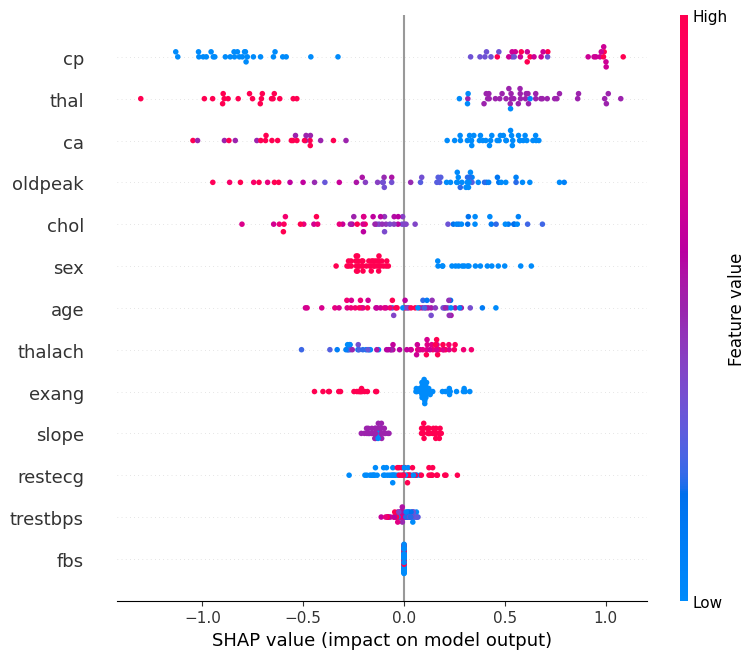

In [ ]:
import shap

explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test, plot_type="dot")
plt.show()

## XGBoost tanpa tuning hyperparameter

In [ ]:
base_xgb = XGBClassifier(random_state=42)
base_xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [ ]:
f1_score(y_test, base_xgb.predict(X_test))

0.8378378378378378

## Regresi Logistic

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(random_state=42)
logreg.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [ ]:
f1_score(y_test, logreg.predict(X_test))

0.8333333333333334

In [ ]:
print(f'Intersep model regresi logistik: {logreg.intercept_}')
print(f'Koefisien model regresi logistik: {logreg.coef_}')

Intersep model regresi logistik: [0.03823948]
Koefisien model regresi logistik: [[ 0.01873045 -1.15228682  0.9531776  -0.01046851 -0.00739663 -0.19680154
   0.50286535  0.03160928 -0.82016072 -0.52177069  0.4263158  -0.57804458
  -0.95240589]]


In [ ]:
print(confusion_matrix(y_test, logreg.predict(X_test)))

[[19  9]
 [ 3 30]]


In [ ]:
print(classification_report(y_test, logreg.predict(X_test)))

              precision    recall  f1-score   support

           0       0.86      0.68      0.76        28
           1       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61

